# MCMC-PESP: Profiling i Optymalizacja

Ten notebook realizuje eksperymenty z **MATH_SPEC.md Sekcja 10.7** i **EXPERIMENTS.md Sekcja 8** ("Skalowanie").

### Sekcje:
1. **Profiling Breakdown** — gdzie spędza czas CPU?
2. **Skalowanie vs Rozmiar** — czas per krok vs |L| i |Γ|
3. **Analiza Wąskich Gardeł** — co optymalizować?

### Pytania badawcze:
- Jaki % czasu to propozycje vs cost evaluation?
- Jak czas per krok skaluje się z rozmiarem sieci?
- Gdzie są bottlenecks do zoptymalizowania?
- Czy cost evaluation skaluje się liniowo z |Γ|?

In [1]:
# ============================================================
# 0. KONFIGURACJA
# ============================================================

MODE = "quick"  # "quick" (~2-3 min) lub "full" (~10-15 min)

SEED = 42

if MODE == "quick":
    N_STEPS_PROFILING = 1000
    N_STEPS_SCALING = 500
else:  # full
    N_STEPS_PROFILING = 5000
    N_STEPS_SCALING = 2000

print(f"Mode: {MODE}")
print(f"Profiling: {N_STEPS_PROFILING} steps")
print(f"Scaling: {N_STEPS_SCALING} steps per scenario")

Mode: quick
Profiling: 1000 steps
Scaling: 500 steps per scenario


In [2]:
import sys
import os
import json
import time
from pathlib import Path
from dataclasses import asdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 5)
matplotlib.rcParams['font.size'] = 11

# Project root
PROJECT_ROOT = Path(os.getcwd()).parent if 'notebooks' in os.getcwd() else Path(os.getcwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.io.synthetic_scenarios import SyntheticScenarioFactory
from src.experiments.analysis.diagnostic_runner import (
    run_profiling_analysis,
    run_scaling_analysis,
)

factory = SyntheticScenarioFactory()
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\User\Zeszyt\pythonProject\mcmc_pesp


---
## 1. Profiling Breakdown

**Pytanie z EXPERIMENTS.md**: Jaki % czasu CPU spędzamy gdzie?

**Co szukać**:
- **Proposal**: generowanie nowego stanu (powinno być < 20%)
- **Cost Evaluation**: obliczanie kosztu (najczęściej bottleneck, 60-80%)
- **Acceptance**: decyzja MH (powinno być < 5%)

**Wnioski**:
- Jeśli Proposal > 30% → optymalizuj propozycje
- Jeśli Cost > 80% → użyj inkrementalnego kosztu lub cache'owania

In [3]:
# Profile różne scenariusze
profiling_scenarios = [
    ('hub', 'easy'),
    ('hub', 'hard'),
    ('multi_hub_mesh', 'easy'),
    ('multi_hub_mesh', 'hard'),
    ('random_network', 'hard/mode'),
]

profiling_results = []

for stype, diff in profiling_scenarios:
    kwargs = {'seed': 42} if stype == 'random_network' else {}
    scenario = factory.create(stype, difficulty=diff, **kwargs)
    
    print(f"\nProfiling: {scenario.metadata.name}...")
    result = run_profiling_analysis(scenario, n_steps=N_STEPS_PROFILING, seed=SEED)
    profiling_results.append(result)
    
    print(f"  Total time: {result.total_time_s:.3f}s")
    for p in result.breakdown:
        print(f"    {p.component:<20}: {p.time_ms:>8.3f} ms/step ({p.percentage:>5.1f}%)")


Profiling: hub_easy...
  Total time: 0.175s
    Proposal            :    0.131 ms/step ( 74.8%)
    Cost Evaluation     :    0.037 ms/step ( 21.1%)
    Acceptance Decision :    0.007 ms/step (  4.0%)

Profiling: hub_hard...
  Total time: 0.232s
    Proposal            :    0.120 ms/step ( 52.0%)
    Cost Evaluation     :    0.105 ms/step ( 45.3%)
    Acceptance Decision :    0.006 ms/step (  2.7%)

Profiling: multi_hub_mesh_easy...
  Total time: 0.142s
    Proposal            :    0.080 ms/step ( 56.6%)
    Cost Evaluation     :    0.057 ms/step ( 40.4%)
    Acceptance Decision :    0.004 ms/step (  2.9%)

Profiling: multi_hub_mesh_medium...
  Total time: 0.208s
    Proposal            :    0.108 ms/step ( 51.9%)
    Cost Evaluation     :    0.094 ms/step ( 45.1%)
    Acceptance Decision :    0.006 ms/step (  3.0%)

Profiling: random_network_medium_seed42...
  Total time: 0.172s
    Proposal            :    0.061 ms/step ( 35.3%)
    Cost Evaluation     :    0.108 ms/step ( 63.0%)
   

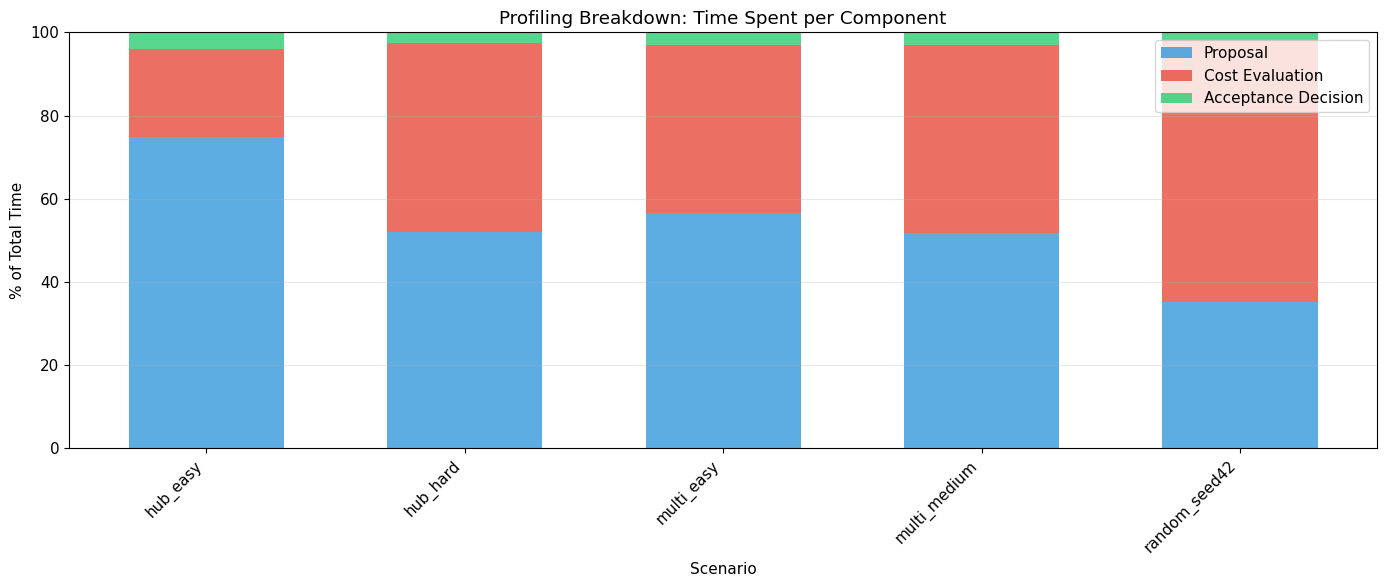

In [4]:
# Visualization: stacked bar chart
fig, ax = plt.subplots(figsize=(14, 6))

scenario_names = [r.scenario_name.split('_')[0] + '_' + r.scenario_name.split('_')[-1] for r in profiling_results]
x = np.arange(len(scenario_names))

# Collect percentages per component
components = profiling_results[0].breakdown
component_names = [c.component for c in components]
colors = ['#3498DB', '#E74C3C', '#2ECC71']

bottoms = np.zeros(len(scenario_names))

for i, comp_name in enumerate(component_names):
    percentages = [next(p.percentage for p in r.breakdown if p.component == comp_name) for r in profiling_results]
    ax.bar(x, percentages, 0.6, bottom=bottoms, label=comp_name, color=colors[i % len(colors)], alpha=0.8)
    bottoms += percentages

ax.set_xlabel('Scenario')
ax.set_ylabel('% of Total Time')
ax.set_title('Profiling Breakdown: Time Spent per Component')
ax.set_xticks(x)
ax.set_xticklabels(scenario_names, rotation=45, ha='right')
ax.legend()
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

---
## 2. Skalowanie vs Rozmiar Sieci

**Pytanie z MATH_SPEC**: Jak czas per krok zależy od |L| i |Γ|?

**Co szukać**:
- **Liniowe skalowanie** z |Γ|: t ∝ |Γ| → dobry znak (inkrementalny koszt)
- **Kwadratowe**: t ∝ |Γ|² → bottleneck do zoptymalizowania
- **Slope**: ms/transfer — ile czasu na obliczenie jednego transferu?

**Analiza**: dopasuj t = a + b|Γ| i sprawdź R²

In [5]:
# Run scaling analysis
print("Running scaling analysis...")
scaling_result = run_scaling_analysis(n_steps=N_STEPS_SCALING, beta=1.0, seed=SEED)

print(f"\n{'Scenario':<35} {'Lines':>5} {'Trans':>5} {'ms/step':>10} {'steps/s':>10}")
print("-" * 70)
for p in scaling_result.points:
    sps = 1000 / p.time_per_step_ms if p.time_per_step_ms > 0 else 0
    print(f"{p.scenario_name:<35} {p.n_lines:>5} {p.n_transfers:>5} {p.time_per_step_ms:>10.3f} {sps:>10.0f}")

Running scaling analysis...

Scenario                            Lines Trans    ms/step    steps/s
----------------------------------------------------------------------
hub_easy                                6     9      0.138       7257
hub_medium                              8    16      0.101       9898
hub_hard                               12    36      0.159       6291
chain_easy                              3     2      0.063      15982
chain_hard                              8     7      0.069      14456
multi_hub_mesh_easy                    12    16      0.122       8204
multi_hub_mesh_medium                  18    25      0.114       8755
random_network_easy_seed42              6     9      0.077      12922
random_network_medium_seed42           12    38      0.160       6264
random_network_hard_seed42             20    82      0.339       2947


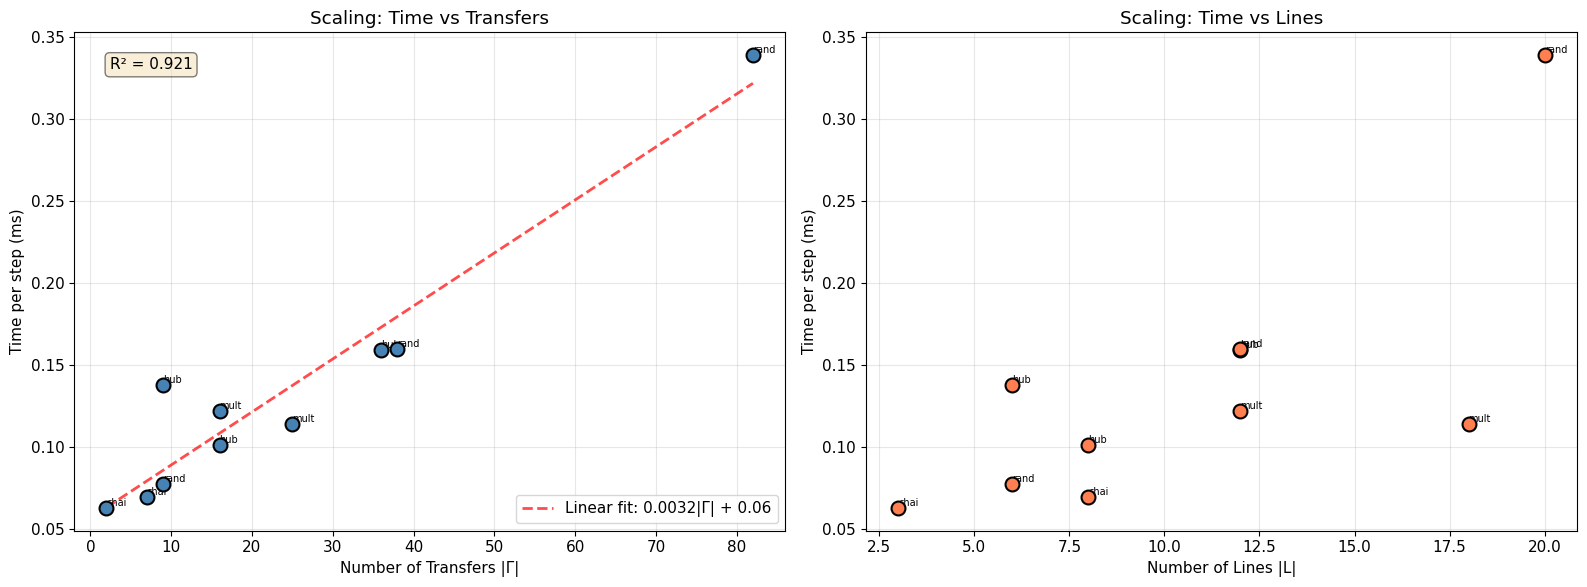

In [6]:
# Scaling plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

n_transfers = np.array([p.n_transfers for p in scaling_result.points])
n_lines = np.array([p.n_lines for p in scaling_result.points])
times = np.array([p.time_per_step_ms for p in scaling_result.points])

# Time vs Transfers
ax1.scatter(n_transfers, times, s=100, c='steelblue', edgecolors='black', linewidth=1.5, zorder=5)
for p in scaling_result.points:
    ax1.annotate(p.scenario_name.split('_')[0][:4], (p.n_transfers, p.time_per_step_ms),
                 fontsize=7, ha='left', va='bottom')

# Linear fit
if len(n_transfers) > 1:
    coeffs = np.polyfit(n_transfers, times, 1)
    fit_line = np.poly1d(coeffs)
    x_fit = np.linspace(n_transfers.min(), n_transfers.max(), 100)
    ax1.plot(x_fit, fit_line(x_fit), 'r--', alpha=0.7, linewidth=2, 
             label=f'Linear fit: {coeffs[0]:.4f}|Γ| + {coeffs[1]:.2f}')
    
    # R²
    residuals = times - fit_line(n_transfers)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((times - np.mean(times))**2)
    r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0
    ax1.text(0.05, 0.95, f'R² = {r_squared:.3f}', transform=ax1.transAxes,
             fontsize=11, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax1.set_xlabel('Number of Transfers |Γ|')
ax1.set_ylabel('Time per step (ms)')
ax1.set_title('Scaling: Time vs Transfers')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Time vs Lines
ax2.scatter(n_lines, times, s=100, c='coral', edgecolors='black', linewidth=1.5, zorder=5)
for p in scaling_result.points:
    ax2.annotate(p.scenario_name.split('_')[0][:4], (p.n_lines, p.time_per_step_ms),
                 fontsize=7, ha='left', va='bottom')

ax2.set_xlabel('Number of Lines |L|')
ax2.set_ylabel('Time per step (ms)')
ax2.set_title('Scaling: Time vs Lines')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Compute ms per transfer
print("\nCost per Transfer:")
print(f"{'Scenario':<35} {'Trans':>5} {'ms/step':>10} {'ms/trans':>10}")
print("-" * 65)

for p in scaling_result.points:
    if p.n_transfers > 0:
        ms_per_trans = p.time_per_step_ms / p.n_transfers
        print(f"{p.scenario_name:<35} {p.n_transfers:>5} {p.time_per_step_ms:>10.3f} {ms_per_trans:>10.4f}")

# Average
avg_ms_per_trans = np.mean([p.time_per_step_ms / p.n_transfers for p in scaling_result.points if p.n_transfers > 0])
print(f"\nAverage: {avg_ms_per_trans:.4f} ms per transfer")


Cost per Transfer:
Scenario                            Trans    ms/step   ms/trans
-----------------------------------------------------------------
hub_easy                                9      0.138     0.0153
hub_medium                             16      0.101     0.0063
hub_hard                               36      0.159     0.0044
chain_easy                              2      0.063     0.0313
chain_hard                              7      0.069     0.0099
multi_hub_mesh_easy                    16      0.122     0.0076
multi_hub_mesh_medium                  25      0.114     0.0046
random_network_easy_seed42              9      0.077     0.0086
random_network_medium_seed42           38      0.160     0.0042
random_network_hard_seed42             82      0.339     0.0041

Average: 0.0096 ms per transfer


---
## 3. Analiza Bottlenecks

**Pytania**:
- Który komponent dominuje czas CPU?
- Czy skalowanie jest liniowe czy kwadratowe?
- Co optymalizować w pierwszej kolejności?

**Rekomendacje**:
1. **Cost Evaluation > 80%** → zaimplementuj cache'owanie lub inkrementalny koszt
2. **Skalowanie nadliniowe** → profiluj cost function (cProfile)
3. **Proposal > 30%** → optymalizuj generator propozycji (Numba, Cython)

In [8]:
# Summary: gdzie optymalizować?
print("=" * 80)
print("ANALIZA BOTTLENECKS I REKOMENDACJE")
print("=" * 80)

# Average breakdown across scenarios
avg_breakdown = {}
for comp_name in component_names:
    percentages = [next(p.percentage for p in r.breakdown if p.component == comp_name) for r in profiling_results]
    avg_breakdown[comp_name] = np.mean(percentages)

print("\n--- AVERAGE TIME BREAKDOWN ---")
for comp, pct in avg_breakdown.items():
    status = ""
    if 'Cost' in comp and pct > 80:
        status = "⚠️  BOTTLENECK — implement incremental cost or caching"
    elif 'Proposal' in comp and pct > 30:
        status = "⚠️  HIGH — optimize proposal generation"
    elif 'Acceptance' in comp and pct > 10:
        status = "⚠️  UNUSUAL — check implementation"
    else:
        status = "✓ OK"
    print(f"  {comp:<25}: {pct:>5.1f}%  {status}")

print("\n--- SCALING ANALYSIS ---")
if len(n_transfers) > 1:
    print(f"  Linear fit: t = {coeffs[0]:.4f}|Γ| + {coeffs[1]:.2f}")
    print(f"  R² = {r_squared:.3f}")
    
    if r_squared > 0.9:
        print("  ✓ GOOD — scaling is approximately linear")
        print(f"  Cost per transfer: {coeffs[0]:.4f} ms")
    else:
        print("  ⚠️  Scaling may be non-linear — investigate cost function")

print("\n--- PRIORITY OPTIMIZATIONS ---")
priorities = []
if avg_breakdown.get('Cost Evaluation', 0) > 80:
    priorities.append("1. Implement incremental cost evaluation (delta_cost)")
if coeffs[0] > 0.01:  # ms per transfer is high
    priorities.append("2. Profile TransferCost computation (use cProfile)")
if avg_breakdown.get('Proposal', 0) > 30:
    priorities.append("3. Optimize proposal generation (use Numba/Cython)")
if not priorities:
    priorities.append("✓ No critical bottlenecks detected")

for p in priorities:
    print(f"  {p}")

print("\n" + "=" * 80)

ANALIZA BOTTLENECKS I REKOMENDACJE

--- AVERAGE TIME BREAKDOWN ---
  Proposal                 :  54.1%  ⚠️  HIGH — optimize proposal generation
  Cost Evaluation          :  43.0%  ✓ OK
  Acceptance Decision      :   2.9%  ✓ OK

--- SCALING ANALYSIS ---
  Linear fit: t = 0.0032|Γ| + 0.06
  R² = 0.921
  ✓ GOOD — scaling is approximately linear
  Cost per transfer: 0.0032 ms

--- PRIORITY OPTIMIZATIONS ---
  3. Optimize proposal generation (use Numba/Cython)



In [9]:
# Save results
output_dir = PROJECT_ROOT / "results" / "profiling"
output_dir.mkdir(parents=True, exist_ok=True)

summary = {
    "mode": MODE,
    "seed": SEED,
    "profiling": [
        {
            "scenario": r.scenario_name,
            "total_time_s": r.total_time_s,
            "breakdown": [
                {"component": p.component, "time_ms": p.time_ms, "percentage": p.percentage}
                for p in r.breakdown
            ],
        }
        for r in profiling_results
    ],
    "scaling": [
        {
            "scenario": p.scenario_name,
            "n_lines": p.n_lines,
            "n_transfers": p.n_transfers,
            "time_per_step_ms": p.time_per_step_ms,
        }
        for p in scaling_result.points
    ],
    "average_breakdown": avg_breakdown,
    "linear_fit": {
        "slope": float(coeffs[0]),
        "intercept": float(coeffs[1]),
        "r_squared": float(r_squared),
    } if len(n_transfers) > 1 else None,
}

output_path = output_dir / f"profiling_{MODE}.json"
with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"Results saved to {output_path}")

Results saved to C:\Users\User\Zeszyt\pythonProject\mcmc_pesp\results\profiling\profiling_quick.json
